# 02  PyTorch CNN
CNN side of the project. Loads the data, trains the CNN, and tests it on clean and degraded images.

### 1. Setup


Change `DRIVE_DATA_ROOT` to wherever your copy of the dataset is (the folder with `Train.csv`, `Test.csv`, `Train/` and `Test/`). If it's in "Shared with me", add a shortcut to My Drive first. Local runs use `Dataset/raw/` instead. Set `USE_DRIVE = False` to use the repo data in Colab.

In [4]:
import sys
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

USE_DRIVE = IN_COLAB
# CHANGE THIS ONE DATASET PATH to your own shared Drive folder/shortcut:
DRIVE_DATA_ROOT = "/content/drive/MyDrive/CP467_Traffic_Signs/data/raw"
print("Running in Colab:", IN_COLAB)
print("Python:", sys.version)

Running in Colab: False
Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


### Mount Drive + get the code
Opening the notebook from GitHub doesn't bring the `src/` files with it, so this clones the repo if it can't find it.

In [5]:
import os
import subprocess

if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
if PROJECT_ROOT is None and IN_COLAB:
    PROJECT_ROOT = Path("/content/CP467GroupProject")
    if not PROJECT_ROOT.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/Davy-Chu/CP467GroupProject.git", str(PROJECT_ROOT)],
            check=True,
        )
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "config.py").is_file():
    raise RuntimeError("Open from the project checkout or change directory to its root first.")

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: c:\Users\paart_yhi80ia\Desktop\Coding Projects\CP467GroupProject


### Dependencies
Colab already has most of these. Only set `INSTALL_DEPENDENCIES = True` if an import fails, then restart the runtime and set it back to False.

In [6]:
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-r", str(PROJECT_ROOT / "requirements.txt")],
        check=True,
    )

import cv2
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import skimage
import sklearn
import torch
import torchvision
import seaborn

for library in (cv2, np, pd, matplotlib, skimage, sklearn, torch, torchvision, seaborn):
    print(f"{library.__name__}: {library.__version__}")

cv2: 5.1.0
numpy: 2.4.6
pandas: 3.1.1
matplotlib: 3.11.2
skimage: 0.26.0
sklearn: 1.9.1
torch: 2.14.1+cu126
torchvision: 0.29.1+cu126
seaborn: 0.13.2


In [7]:
from src.config import (
    NUM_CLASSES, IMAGE_SIZE, RANDOM_SEED, REPO_DATA_ROOT,
    RESULTS_DIR, MODELS_DIR, CONDITIONS, DEGRADATION_PARAMS,
    get_data_root, seed_everything,
)
from src.data_utils import (
    validate_dataset, load_metadata, load_image,
    make_train_validation_split, split_fingerprint,
)
from src.degradations import (
    apply_condition, reduce_brightness, add_noise, apply_motion_blur,
    equalize_histogram, gaussian_filter,
)

seed_everything()
DATA_ROOT = get_data_root(USE_DRIVE, DRIVE_DATA_ROOT)
print("Selected data root:", DATA_ROOT)
print("Repository fallback:", REPO_DATA_ROOT)
print("Shared conditions:", DEGRADATION_PARAMS)

Selected data root: C:\Users\paart_yhi80ia\Desktop\Coding Projects\CP467GroupProject\Dataset\raw
Repository fallback: C:\Users\paart_yhi80ia\Desktop\Coding Projects\CP467GroupProject\Dataset\raw
Shared conditions: {'brightness': {'factor': 0.5}, 'noise': {'std': 0.05}, 'motion_blur': {'kernel_size': 9}}


## 2. GPU / Device Check
Switch the Colab runtime to GPU before training (Runtime > Change runtime type). CPU works but training is slow.

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("CPU selected. Enable a Colab GPU before CNN training if available.")

cuda
NVIDIA GeForce RTX 3070


## 3. Load Dataset

Checks that all 43 classes and all 39,209 train / 12,630 test images are there. By default it only opens one image per class, use `check_images="all"` for a full check (slow).

In [ ]:
# make sure this passes before training anything
training_metadata, test_metadata = validate_dataset(DATA_ROOT, check_images="sample")
train_metadata, validation_metadata = make_train_validation_split(training_metadata)
SPLIT_ID = split_fingerprint(train_metadata, validation_metadata)
print(f"Training subset: {len(train_metadata):,}")
print(f"Validation subset: {len(validation_metadata):,}")
print(f"Official test (final evaluation only): {len(test_metadata):,}")
print("Split ID (must match across teammates):", SPLIT_ID)

Dataset root: C:\Users\paart_yhi80ia\Desktop\Coding Projects\CP467GroupProject\Dataset\raw
Train/: 39,209 PNG images present (expected 39,209).
Decoding 43 Train images (sample check)...
Train.csv: 39,209 rows, 43 classes.
Test/: 12,630 PNG images present (expected 12,630).
Decoding 43 Test images (sample check)...
Test.csv: 12,630 rows, 43 classes.
Dataset validation passed (image decoding: sample).
Training subset: 31,367
Validation subset: 7,842
Official test (final evaluation only): 12,630
Split ID (must match across teammates): 2947e8e993860c74


## 4. DataLoader Setup
Apply `apply_condition` to the common resized RGB image before converting to tensors. Reuse optional shared preprocessing helpers; never augment validation/test randomly.



In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# load the whole split into the memory once, this si faster than reading pngs from every epoch
def load_split_into_memory(metadata, condition="clean"):
    images = []
    labels = []
    for i in range(len(metadata)):
        path = metadata.iloc[i].Path
        img = load_image(DATA_ROOT, path)
        img = apply_condition(img, condition, image_id=path)
        images.append(img)
        labels.append(metadata.iloc[i].ClassId)
    images =np.array(images)
    labels = np.array(labels)

    # Since pytorch expects flaots o-1 and channels first (N,C,H, W):
    x = images.astype(np.float32) / 255.0
    x = torch.from_numpy(x)
    x = x.permute(0, 3, 1, 2)
    y = torch.from_numpy(labels).long()
    return x, y

x_train, y_train = load_split_into_memory(train_metadata, condition="clean")
print(f"Train loaded: {x_train.shape}")

x_val, y_val = load_split_into_memory(validation_metadata, condition="clean")
print(f"Validation loaded: {x_val.shape}")

# Only shuffle the training, seeded to rerun come in the same order
g = torch.Generator()
g.manual_seed(RANDOM_SEED)
train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_val, y_val)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=g)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)


Train loaded: torch.Size([31367, 3, 32, 32])
Validation loaded: torch.Size([7842, 3, 32, 32])


## 5. CNN Architecture

In [11]:
import torch.nn as nn

# 3 Conversion blocks, in each one it finds features then halves the size of the iamge

class TrafficCnn(nn.Module):
    def __init__(self):
        super().__init__()
        #block 1 3 colour channels go in, 32 filters out 32x32 becomes 16x16
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        #block 2: 16x16 becomes 8x8, 32 filters go in, 64 filters out
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        #block 3: 8x8 becomes 4x4, 64 filters go in, 128 filters out
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3 , padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        #After 3 poools we have 128 channels of 4x4 
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv3(x)
        x = self.relu(x)
        x = self.pool(x)

        x= torch.flatten(x, 1) # 128x4x4 -> 2048 long vector
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x) # 43 scores, one per sign class
        return x

model = TrafficCnn()
model.to(device)

#Count the weights for the report
total_params = 0
for p in model.parameters():
    total_params += p.numel()
print(f"Total parameters: {total_params:,}")

Total parameters: 628,843


## 6. Training

In [19]:
import time
import copy

EPOCHS = 10
LEARNING_RATE = 0.001

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# msave every epoch so that curves can be plotted in section 7
train_losses = []
val_losses = []
train_accs = []
val_accs = []

best_val_acc = 0.0

best_epoch = 0
best_weights = None

# gpu runs async so sync before starting the timer
if device.type == "cuda":
    torch.cuda.synchronize()
start_time = time.perf_counter()

for epoch in range(EPOCHS):
    # train part
    model.train()  # turns the dropout on
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()  # clear all of the gradients from the last batch
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss = running_loss + loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct = correct + (preds == labels).sum().item()
        total = total + labels.size(0)
    train_loss = running_loss / total
    train_acc = correct / total

    # val part, no gradients needed
    model.eval()  # turns dropout off
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)

            running_loss = running_loss + loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct = correct + (preds == labels).sum().item()
            total = total + labels.size(0)
    val_loss = running_loss / total
    val_acc = correct / total

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    # keep a copy of the best epoch so far
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(model.state_dict())

    print(f"epoch {epoch + 1}/{EPOCHS}: train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

if device.type == "cuda":
    torch.cuda.synchronize()
training_time = time.perf_counter() - start_time
print(f"Time training took: {training_time:.1f} s")
print(f"Best epoch {best_epoch} with val acc: {best_val_acc:.4f}")

epoch 1/10: train loss 2.5632 acc 0.2608 | val loss 1.3912 acc 0.5432
epoch 2/10: train loss 1.1012 acc 0.6306 | val loss 0.5089 acc 0.8363
epoch 3/10: train loss 0.5037 acc 0.8311 | val loss 0.1978 acc 0.9388
epoch 4/10: train loss 0.2779 acc 0.9091 | val loss 0.1104 acc 0.9711
epoch 5/10: train loss 0.1937 acc 0.9378 | val loss 0.0680 acc 0.9856
epoch 6/10: train loss 0.1375 acc 0.9543 | val loss 0.0527 acc 0.9872
epoch 7/10: train loss 0.1084 acc 0.9650 | val loss 0.0467 acc 0.9880
epoch 8/10: train loss 0.0927 acc 0.9704 | val loss 0.0378 acc 0.9917
epoch 9/10: train loss 0.0807 acc 0.9745 | val loss 0.0457 acc 0.9880
epoch 10/10: train loss 0.0716 acc 0.9767 | val loss 0.0409 acc 0.9915
Time training took: 36.5 s
Best epoch 8 with val acc: 0.9917


## 7. Validation

Loaded  in best weights from epoch #8 (val acc 0.9917)


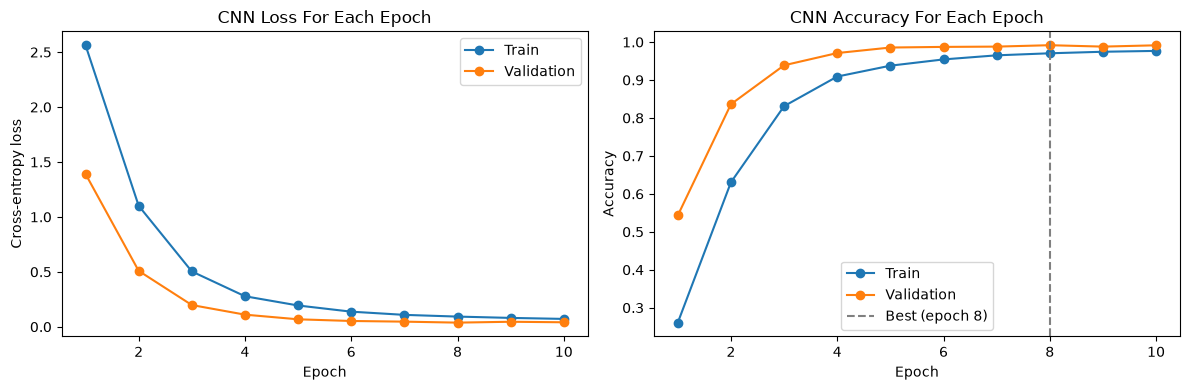

In [ ]:
# place the best epoch back in so that the testing uses it, but not epoch 10
model.load_state_dict(best_weights)
model.eval()

print(f"Loaded  in best weights from epoch #{best_epoch} (val acc {best_val_acc:.4f})")

PLOTS_DIR = RESULTS_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

epoch_nums = []
for e in range(EPOCHS):
    epoch_nums.append(e + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left side is the  loss
axes[0].plot(epoch_nums, train_losses, marker="o", label="Train")
axes[0].plot(epoch_nums, val_losses, marker="o", label="Validation")
axes[0].set_title("CNN Loss For Each Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

# right side is the accuracy the dashed line marks the epoch that we kept
axes[1].plot(epoch_nums, train_accs, marker="o", label="Train")
axes[1].plot(epoch_nums, val_accs, marker="o", label="Validation")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best (epoch {best_epoch})")
axes[1].set_title("CNN Accuracy For Each Epoch")
axes[1].set_xlabel("Epoch")

axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(PLOTS_DIR / "cnn_training_curves.png", dpi=150)
plt.show()

## 8. Clean Test Evaluation

In [22]:
from sklearn.metrics import accuracy_score, f1_score

BATCH_SIZE = 64

# run the model on a whole split and give back the predicted class for each image

# function since we can reuse it for clean + 3 degraed test sets
def predict(x):
    dataset = TensorDataset(x)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)
    all_preds = []
    model.eval() # Dropout ius off otherwise the results will change every time its ran
    with torch.no_grad(): #not training so no need to calculate the gradients, it wil waste time and memory
        for batch in loader:
            images = batch[0]
            images = images.to(device)
            outputs = model(images)    #43 scores per image
            preds = outputs.argmax(dim=1)
            preds = preds.cpu()  # back to cpu so numpy can utilize it
            all_preds.append(preds)
    all_preds = torch.cat(all_preds)
    all_preds = all_preds.numpy()
    return all_preds

# Test set, only use this since training is done
x_test_clean, y_test = load_split_into_memory(test_metadata, condition="clean")
print(f"Test loaded: {x_test_clean.shape}")
y_true = y_test.numpy()

clean_preds = predict(x_test_clean)

# same metric settings as the svm side so numbers are comparable
all_labels = list(range(NUM_CLASSES))
clean_acc = accuracy_score(y_true, clean_preds)
clean_f1 = f1_score(y_true, clean_preds, average="macro", labels=all_labels, zero_division=0)
print(f"clean test: accuracy {clean_acc:.4f}, macro f1 {clean_f1:.4f}")

# one entry per condition, these go into metrics.csv in section 12
test_results = []
clean_result = {}
clean_result["condition"] = "clean"
clean_result["accuracy"] = clean_acc
clean_result["macro_f1"] = clean_f1
test_results.append(clean_result)

# keep the images and predictions per condition for the sample outputs figure later
test_imgs = {}
test_preds = {}
test_imgs["clean"] = x_test_clean
test_preds["clean"] = clean_preds

Test loaded: torch.Size([12630, 3, 32, 32])
clean test: accuracy 0.9398, macro f1 0.9078


## 9. Degraded Test Evaluation

brightness test: accuracy 0.9124, macro f1 0.8707
noise test: accuracy 0.8994, macro f1 0.8625
motion_blur test: accuracy 0.7382, macro f1 0.6980

clean: accuracy 0.9398, macro f1 0.9078, drop 0.0000
brightness: accuracy 0.9124, macro f1 0.8707, drop 0.0275
noise: accuracy 0.8994, macro f1 0.8625, drop 0.0404
motion_blur: accuracy 0.7382, macro f1 0.6980, drop 0.2017


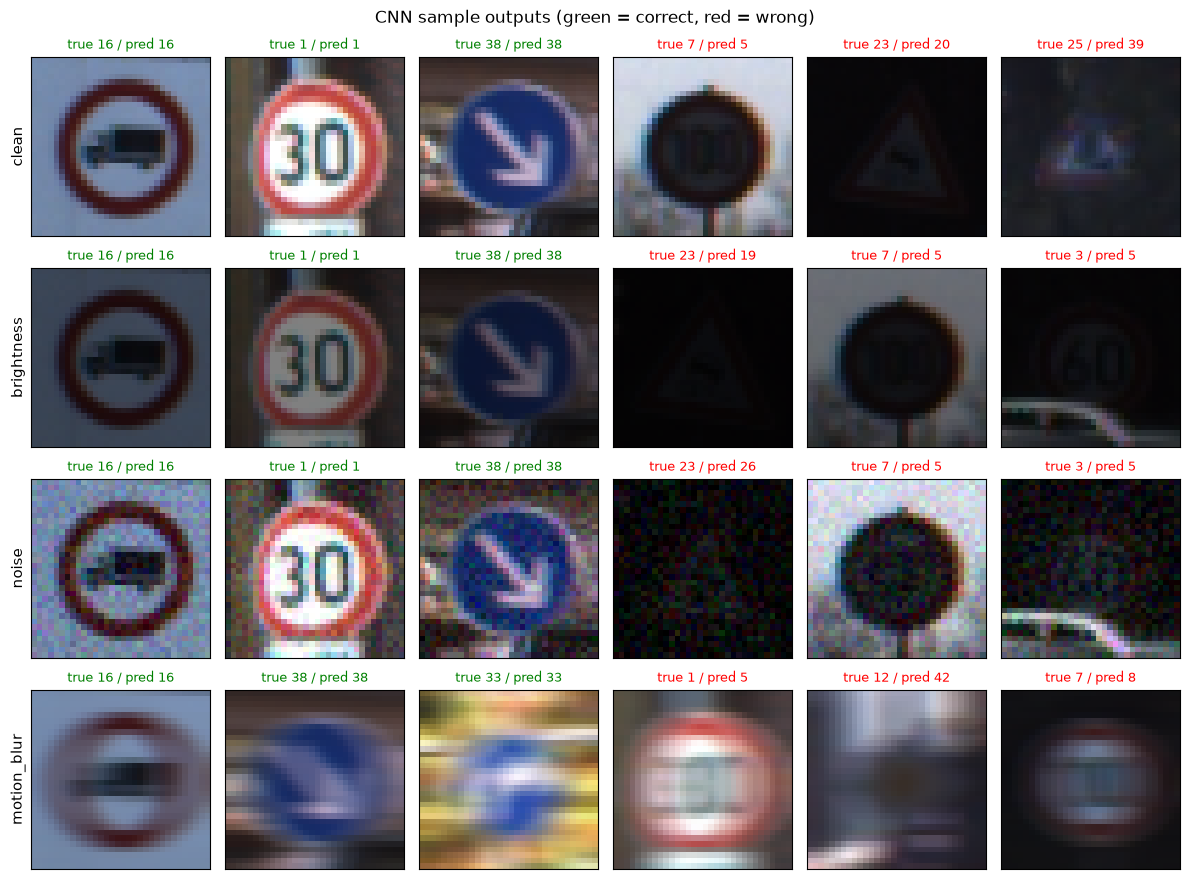

In [ ]:
# Constants to show per row in the original sample figure
NUM_RIGHT = 3
NUM_WRONG = 3

# The same test images but made darker / noisy / blurry
# Apply_condition seeds the noise with the image path so the svm side gets the exact same noise
for condition in CONDITIONS:
    if condition == "clean":
        continue  # already did clean in section 8

    # y_test_cond is the same as y_test, labels dont change with degradation
    x_test_cond, y_test_cond = load_split_into_memory(test_metadata, condition=condition)
    cond_preds = predict(x_test_cond)

    cond_acc = accuracy_score(y_true, cond_preds)
    cond_f1 = f1_score(y_true, cond_preds, average="macro", labels=all_labels, zero_division=0)
    print(f"{condition} test: accuracy {cond_acc:.4f}, macro f1 {cond_f1:.4f}")

    cond_result = {}
    cond_result["condition"] = condition
    cond_result["accuracy"] = cond_acc
    cond_result["macro_f1"] = cond_f1
    test_results.append(cond_result)

    test_imgs[condition] = x_test_cond
    test_preds[condition] = cond_preds

# Summarize, the drop = how much accuracy we lost vs clean
print()
for result in test_results:
    drop = clean_acc - result["accuracy"]
    print(f"{result['condition']}: accuracy {result['accuracy']:.4f}, macro f1 {result['macro_f1']:.4f}, drop {drop:.4f}")

# sample outputs for the report: first 3 right and first 3 wrong for each condition
fig, axes = plt.subplots(len(CONDITIONS), NUM_RIGHT + NUM_WRONG, figsize=(12, 9))

for row in range(len(CONDITIONS)):
    condition = CONDITIONS[row]
    preds = test_preds[condition]

    right_idx = []
    wrong_idx = []
    for i in range(len(y_true)):
        if preds[i] == y_true[i] and len(right_idx) < NUM_RIGHT:
            right_idx.append(i)
        if preds[i] != y_true[i] and len(wrong_idx) < NUM_WRONG:
            wrong_idx.append(i)
    picked = right_idx + wrong_idx

    for col in range(len(picked)):
        i = picked[col]
        img = test_imgs[condition][i]
        img = img.permute(1, 2, 0)  # =back to (H,W,C) so matplotlib can show it
        img = img.numpy()

        ax = axes[row, col]
        ax.imshow(img)
        # Hide ticks but not the whole axis, otherwise the row label disappears
        ax.set_xticks([])
        ax.set_yticks([])

        if preds[i] == y_true[i]:
            color = "green"
        else:
            color = "red"
        ax.set_title(f"true {y_true[i]} / pred {preds[i]}", color=color, fontsize=9)

    axes[row, 0].set_ylabel(condition, fontsize=11)

fig.suptitle("CNN sample outputs (green = correct, red = wrong)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "cnn_sample_outputs.png", dpi=150)
plt.show()

## 10. Timing

In [ ]:
#Constant for how many times to run the inference timing
NUM_TIMING_RUNS = 3

# The first gpu call is always slow because the cuda needs to warm up so do a test run first
warmup_preds = predict(x_test_clean)
# time the whole clean test set a few times and average it
# only times the model, not loading pngs, svm side should do the same
run_times = []
for run in range(NUM_TIMING_RUNS):
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    timing_preds = predict(x_test_clean)


    if device.type == "cuda":
        torch.cuda.synchronize()  # wait for the gpu to actually finish
    end = time.perf_counter()
    run_times.append(end - start)
    print(f"run {run + 1}: {end - start:.3f} s")

average_time = sum(run_times) / len(run_times)
num_images = len(x_test_clean)
inference_ms = average_time / num_images * 1000  # the seconds per image -> ms per image

print(f"Training time: {training_time:.1f}s")

if device.type == "cuda":
    hardware = torch.cuda.get_device_name(0)
else:
    hardware = "cpu"
print(f"Inference: {inference_ms:.4f} ms per image (batch {BATCH_SIZE}, {hardware})")

run 1: 0.569 s
run 2: 0.438 s
run 3: 0.437 s
Training time: 36.5s
Inference: 0.0381ms per image (batch 64, NVIDIA GeForce RTX 3070)


## 11. Confusion Matrix

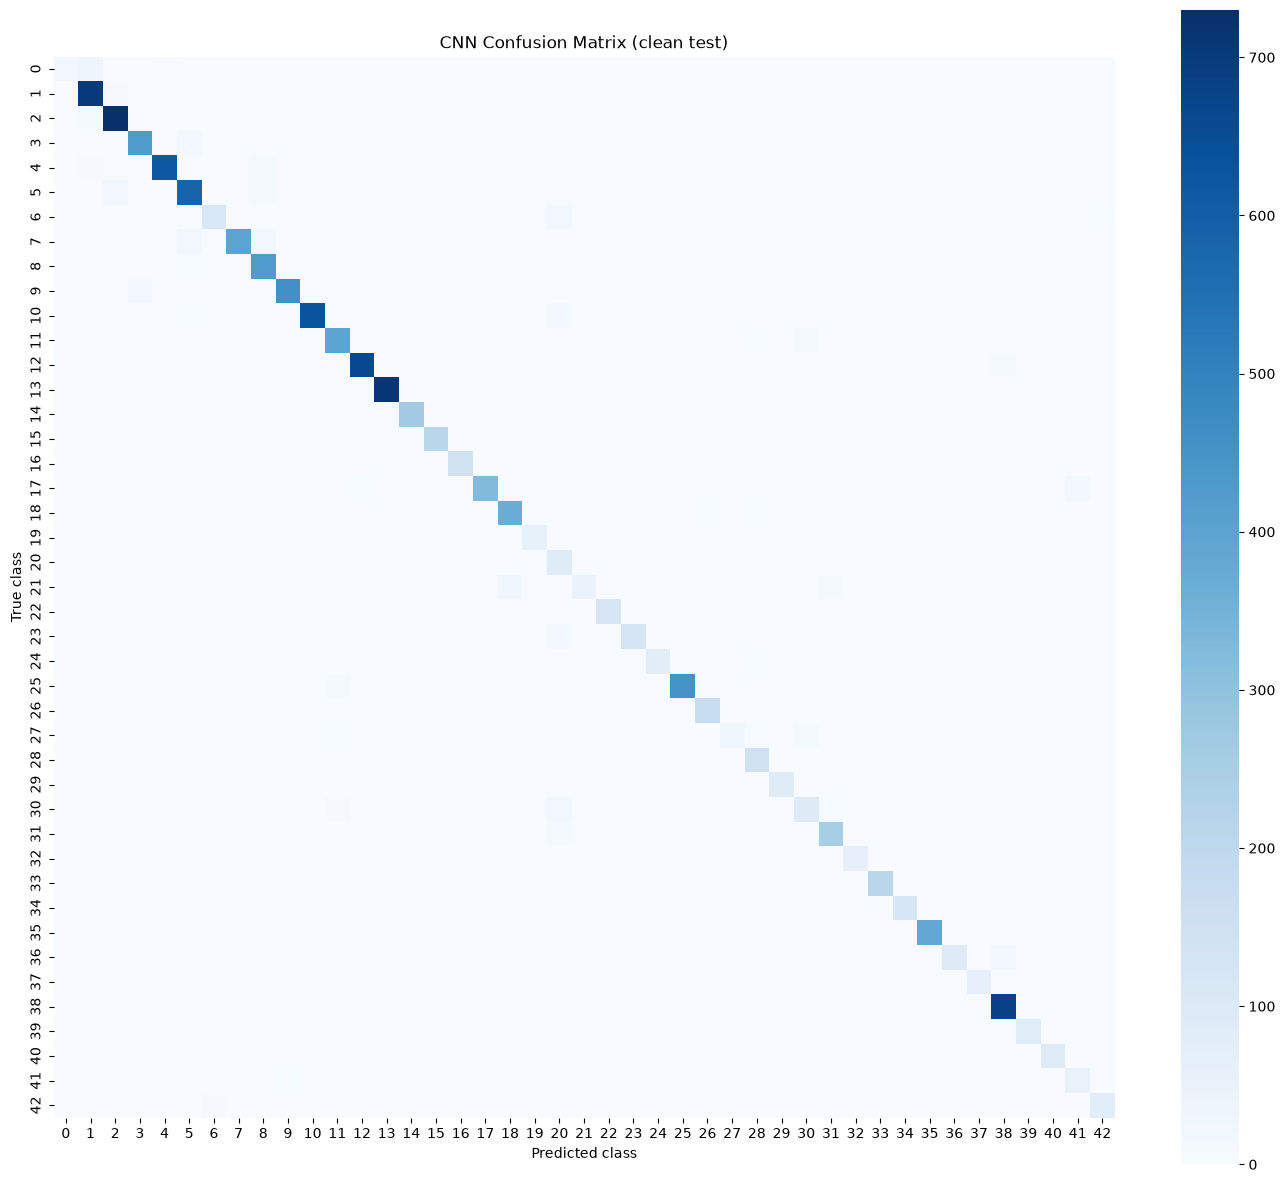

true 0 predicted as 1: 32 times
true 21 predicted as 18: 31 times
true 36 predicted as 38: 24 times
true 7 predicted as 5: 24 times
true 6 predicted as 20: 23 times


In [ ]:
from sklearn.metrics import confusion_matrix

CM_DIR = RESULTS_DIR / "confusion_matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

# Rows = true class, columns = what the model guessed, diagonal = correct
cm = confusion_matrix(y_true, clean_preds, labels=all_labels)

fig, ax = plt.subplots(figsize=(14, 12))
# no numbers in the boxes, 43x43 is way too crowded
seaborn.heatmap(cm, cmap="Blues", square=True, xticklabels=all_labels, yticklabels=all_labels, ax=ax)
ax.set_title("CNN Confusion Matrix (clean test)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.savefig(CM_DIR / "cnn_clean.png", dpi=150)
plt.show()

# The plot is mostly diagonal so also list the biggest mistakes for the report
mistakes = []
for t in range(NUM_CLASSES):
    for p in range(NUM_CLASSES):
        if t != p and cm[t, p] > 0:
            mistakes.append((cm[t, p], t, p))
mistakes.sort(reverse=True)  # biggest count comes first


for k in range(5):
    count = mistakes[k][0]
    t = mistakes[k][1]
    p = mistakes[k][2]
    print(f"True {t} predicted as {p}: {count} times")

## 12. Save Model / Results


In [26]:
#Constants, need to remember to change PREPROCESSING later when we test hist eq / gaussian
MODEL_NAME = "cnn"
PREPROCESSING = "none"
MODEL_PATH = MODELS_DIR / "cnn.pt"
METRICS_PATH = RESULTS_DIR / "metrics.csv"

# save just the weights (state_dict), smaller and the normal way to do it
MODELS_DIR.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), MODEL_PATH)
size_mb = MODEL_PATH.stat().st_size / 1024 / 1024
print(f"saved model to {MODEL_PATH} ({size_mb:.2f} MB)")

# add one row per condition, the header is already in the file so dont write it again
# newline="" so windows doesnt sneak \r into the file for everyone else
with open(METRICS_PATH, "a", newline="") as f:
    for result in test_results:
        row = []
        row.append(MODEL_NAME)
        row.append(result["condition"]) #
        row.append(PREPROCESSING)
        row.append(f"{result['accuracy']:.4f}")
        row.append(f"{result['macro_f1']:.4f}")
        row.append(f"{training_time:.1f}")
        row.append(f"{inference_ms:.4f}")  # timed on clean, speed doesnt change with condition
        row.append(str(RANDOM_SEED))
        row.append(SPLIT_ID) 
        line = ",".join(row) # csv of values 
        f.write(line + "\n")
        print(line)

saved model to C:\Users\paart_yhi80ia\Desktop\Coding Projects\CP467GroupProject\models\cnn.pt (2.40 MB)
cnn,clean,none,0.9398,0.9078,36.5,0.0381,42,2947e8e993860c74
cnn,brightness,none,0.9124,0.8707,36.5,0.0381,42,2947e8e993860c74
cnn,noise,none,0.8994,0.8625,36.5,0.0381,42,2947e8e993860c74
cnn,motion_blur,none,0.7382,0.6980,36.5,0.0381,42,2947e8e993860c74
